# The social planner's problem, on the `new_fixed` model

`new_fixed.ipynb` corrects `new.ipynb` but keeps its objective: minimise
$\sum_t c_t^2 + \sum_t \pi_t^2$. That loss has no microfoundation in this model — there is
no Calvo price dispersion and no wage rigidity, so inflation carries no welfare cost, and
`new_fixed`'s own section 6 says as much. This notebook keeps `new_fixed`'s **model** and
replaces its **objective** with the planner's: choose the nominal rate path to maximise

$$U=\sum_t \beta^t \zeta_t\big[u(C_t)-\chi\,v(N_t)\big],\qquad
v(N)=\tfrac{N^{1+\eta}}{1+\eta}.$$

Inherited from `new_fixed` unchanged:

* **the corrected rate matrix** (its correction 3) — row $t$ carries $i_{t-k}$, so a firm
  delivering at $t$ discounts over its actual production window and the rate's influence
  runs to $t+\tau_i-1$ rather than dying at $t=L$;
* **the CES price index** $P=1/\tilde A$, hence $\pi_t=-(a_t-a_{t-1})$;
* **physical consumption** $c_t=x_t+\varphi_{ya}a_t-d_t$ with $d_t=\log(\tilde A_t/Z_t)$;
* the calibration of $\tau_i$ from inventory/COGS data.

Changed from `new_fixed`:

1. **The objective** — household utility, not $\sum c^2+\sum\pi^2$.
2. **The natural rate is corrected.** `new_fixed` uses $r^n_t=\rho-\texttt{dem}_t$, dropping
   the $\gamma\,\Delta y^n$ term. That is an error rather than a convention: substituting
   $y=y^n+x$ into the household Euler equation gives
   $x_t=x_{t+1}-\tfrac1\gamma[i_t-\pi_{t+1}-\rho+\texttt{dem}_t-\gamma\Delta y^n]$, so the
   term is precisely what makes the gap recursion equivalent to the household's own
   optimality condition. Without it the computed path violates that condition by up to
   $0.5$pp and the TFP fixed-rate gap comes out about twice its true size with the wrong
   sign. `natural_rate_dy=False` reproduces `new_fixed`'s version for comparison.
3. **$\gamma=2$**, matching `planner_consumption_deviation.ipynb` rather than `new_fixed`'s
   $\gamma=1$. Section 8 explains why: at $\gamma=1$ the TFP experiment is degenerate.
4. The $3\%$ TFP shock is run alongside the $1\%$ demand shock.

**Interest rate changes affect prices, and that is the whole mechanism.** The rate reaches
the price level only through $\beta^{\tau_i}$ in firms' cost, so a rate move is imposed not
just on period $t$ but on every delivery date in $t,\dots,t+\tau_i$. Section 3 verifies the
channel is live before anything is optimised, and contrasts it with the truncated matrix
where it is not.

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

## 1. Calibration

Identical to `new_fixed.ipynb`.

In [19]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE = 0.01
sigma = 5
gamma = 2.0               # 1.0 is new_fixed's calibration (log utility); 2.0 matches
                          # planner_consumption_deviation.  See section 8 -- gamma = 1
                          # is a knife edge at which the TFP experiment is degenerate.
eta = 2.0
chi = 1.0                        # C_ss = N_ss = A_ss = 1
PHI_YA = (1 + eta) / (gamma + eta)

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

A_SHOCK = 0.97                   # 3 per cent TFP decline
D_SHOCK = 0.01                   # 1 per cent demand shock
T = 30

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA}, chi={chi}, rho={rho:.6f}')
print(f'A shock = {A_SHOCK} ({100*(1-A_SHOCK):.0f}%),  demand shock = {100*D_SHOCK:.0f}%')
print(f'utility: {"log C" if abs(gamma-1) < 1e-12 else f"C^(1-{gamma})/(1-{gamma})"}'
      f'   -- note phi_ya = 1 exactly at gamma = 1; section 8 returns to this')

gamma=2.0, eta=2.0, phi_ya=0.75, chi=1.0, rho=0.010000
A shock = 0.97 (3%),  demand shock = 1%
utility: C^(1-2.0)/(1-2.0)   -- note phi_ya = 1 exactly at gamma = 1; section 8 returns to this


In [20]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)          # physical output per firm, no discount factor

print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')
print(f'tau ranges over [{tvals.min()}, {tvals.max()}];  counts by tau = {np.bincount(tvals)}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_19535/1103498615.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269
tau ranges over [0, 13];  counts by tau = [ 1 31 97 66 48 18  1  2  0  2  1  1  0  1]


In [21]:
def generate_pattern_array_with_extra_rows(tau, shock=A_SHOCK):
    """Staggering matrix: which firms have re-optimised by period t."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape,
      f'-> TFP shock fully worked through by t = {A_PATTERN.shape[0] - 1}')

staggering matrix: (16, 269) -> TFP shock fully worked through by t = 15


## 2. The model

`rate_matrix` and the price index are `new_fixed.ipynb`'s. Two points are worth stating
explicitly because both were wrong in the `planner_*` lineage.

**The rate matrix keeps its history.** `irl[t, k]` is the rate that prevailed at date
$t-k$, so a firm with lag $\tau_i$ delivering at $t$ is discounted over $[t-\tau_i+1,\,t]$.
The `truncated=True` branch reproduces the old construction, which wrote only the top-left
$L\times L$ block and left every row $t\ge L$ at $\rho$ — killing the propagation entirely.

**The price index is the CES one.** Firms price at $p_i \propto 1/\text{tprod}_i$, so

$$P=\Big(\textstyle\sum_i p_i^{1-\sigma}\Big)^{\frac1{1-\sigma}}
   \propto\Big(\textstyle\sum_i \text{tprod}_i^{\sigma-1}\Big)^{\frac1{1-\sigma}}
   =\frac1{\tilde A},
\qquad\Rightarrow\qquad \pi_t=-(a_t-a_{t-1}).$$

The exponent flips sign when $\text{tprod}$ is inverted. The economy is competitive, so
$p_i$ is marginal cost; the wage is a constant of proportionality and drops out of
$\Delta\log P$ either way.

In [22]:
TAUMAX_PAD = int(tvals.max()) + 2
T_PLUS_TAU = np.arange(T)[:, None] + tvals[None, :]   # delivery date of the batch started at t


def rate_matrix(r, T=T, truncated=False):
    """Row t = the rates a firm delivering at t discounts over, most recent lag first.

    irl[t, k] = the nominal rate at date t - k.  `truncated=True` is the old construction
    (`irl[0:L, :L] = blk`), which leaves every row t >= L at rho so the rate path stops
    mattering at t = L instead of t = L + tau_i - 1.
    """
    r = np.asarray(r, float)
    L = len(r)
    if truncated:
        irl = np.ones((T, T)) * rho
        blk = np.full((L, L), rho, dtype=float)
        for i in range(L):
            blk[i, :i + 1] = r[i::-1]
        irl[0:L, :L] = blk
        return irl
    idx = np.subtract.outer(np.arange(T), np.arange(T))          # idx[t, k] = t - k
    return np.where((idx >= 0) & (idx < L), r[np.clip(idx, 0, L - 1)], rho)


def aggregates(r, T=T, a_shock=False, time_to_build=True, shock_ttb=None, truncated=False):
    """(a_nat, d, pi, lab_unit): TFP, its discount content, inflation, and firm labour.

    `lab_unit[t, i]` is the labour EMBODIED IN firm i's date-t delivery, per unit of Y_t:
        y_{i,t}/z_i = Y_t * A_til_t^{-sigma} * disc_{t,i}^sigma * zp_{t,i}^{sigma-1},
    from p_i = W/(disc_i zp_i) (price = marginal cost), P = W/A_til, and the CES
    demand y_i = (p_i/P)^{-sigma} Y.

    It is deliberately NOT summed here.  Date-t EMPLOYMENT is the labour *started* at t,
    which is delivered at t + tau_i, so the aggregate needs a firm-specific time shift
    (see `solve`).  Summing this array along i would give the labour embodied in date-t
    deliveries, which is a different object and was hired tau_i periods earlier.
    """
    if shock_ttb is None:
        shock_ttb = time_to_build
    irl = rate_matrix(r, T, truncated)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    disc = ce[:, tvals if time_to_build else np.zeros_like(tvals)]

    sm = np.ones((T, NFIRMS))
    if a_shock:
        if shock_ttb:
            sm[0:15] = A_PATTERN[1:]      # shock arrives in cohorts
        else:
            sm[0, :] = A_SHOCK            # every firm hit at once

    zp = Z_PHYS * sm
    tprod = disc * zp
    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))       # measured (cost) TFP
    Z_t = np.sum(zp**(sigma - 1), axis=1)**(1 / (sigma - 1))            # physical

    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]
    pi = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])                 # P = 1 / Atil
    lab_unit = A_til[:, None]**(-sigma) * disc**sigma * zp**(sigma - 1)
    return a_nat, d, pi, lab_unit


def pref_shifter(dem):
    """z_t implied by the demand shock: dem_t = z_{t+1} - z_t, normalised z_T = 0."""
    dem = np.asarray(dem, float)
    return -np.cumsum(dem[::-1])[::-1]


def solve(r, T=T, a_shock=False, demand=None, time_to_build=True, shock_ttb=None,
          truncated=False, natural_rate_dy=True, euler_on='physical'):
    """Euler equation, then consumption = gap + natural level, physically valued."""
    a_nat, d, pi, lab_unit = aggregates(r, T, a_shock, time_to_build, shock_ttb, truncated)
    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    pi_fwd = np.r_[pi[1:], 0.0]

    # Natural rate.  new_fixed.ipynb uses r_nat = rho - dem, dropping the gamma * dy^n
    # term; that is an error, not a convention.  Writing y = y^n + x in the household
    # Euler equation gives
    #     x_t = x_{t+1} - (1/gamma)[ i_t - pi_{t+1} - rho + dem_t - gamma * dy^n ],
    # so the term is exactly what makes the gap recursion equivalent to the household's
    # own optimality condition.  Without it the computed path violates that condition by
    # up to 0.5pp, and the TFP fixed-rate gap comes out roughly twice its true size with
    # the wrong sign.  `natural_rate_dy=False` reproduces new_fixed's version.
    # Which consumption concept does the household's Euler equation apply to?
    #   'measured' : it holds on y = c + d.  phi_ya then multiplies MEASURED TFP while d
    #                is subtracted at coefficient 1, leaving a residual -(1-phi_ya)*a_nat,
    #                so a purely discount-driven fall in P LOWERS physical consumption
    #                though it moves no quantity anywhere in the model.
    #   'physical' : it holds on c itself.  phi_ya multiplies PHYSICAL productivity and the
    #                discount content passes one-for-one into the price level.  The rate
    #                then reaches consumption through pi in the Euler equation, so a cut
    #                raises consumption for the ~tau periods the price level takes to
    #                recover.  See interest_rate_shock.ipynb.
    # The two coincide exactly at gamma = 1, where phi_ya = 1.
    a_phys_pre = a_nat - d
    y_nat = PHI_YA * (a_nat if euler_on == 'measured' else a_phys_pre)
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + (gamma * dy if natural_rate_dy else 0.0)

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]

    a_phys = a_nat - d
    if euler_on == 'measured':
        c_meas = x + PHI_YA * a_nat         # discount still inside
        c = c_meas - d
    else:
        c = x + PHI_YA * a_phys             # the Euler holds on c itself
        c_meas = c + d

    # Labour.  EQUILIBRIUM hours are the exact firm sum, n = c + omega (see aggregates).
    #
    # EFFICIENT hours are NOT c^e + omega.  A planner allocating y_i directly solves
    #     max CES(y)  s.t.  sum_i y_i/z_i = N   ->   y_i propto z_i^sigma  ->  N = Y/Z,
    # i.e. the first best has no discount dispersion at all and lands exactly on the
    # physical index.  So the first-best benchmark is unchanged:
    #     c^e = phi_ya a^phys,  n^e = c^e - a^phys = (phi_ya - 1) a^phys.
    # The residual is misallocation: relative prices go as 1/(disc_i z_i) while relative
    # costs go as 1/z_i, so tau-dispersion pushes production away from the efficient mix.
    #     m = omega + a^phys = log(Omega_t Z_t) >= 0,   m = 0 iff disc_i is common.
    # m depends on the rate path, so unlike a^phys it is NOT policy-invariant: the labour
    # gap is the consumption gap PLUS a term the planner can move.
    # EMPLOYMENT, timed correctly.  All of a batch's labour is hired at its start date,
    # so date-t employment is the labour behind the deliveries dated t + tau_i:
    #     l[t, i] = y_{i,t}/z_i  (labour embodied in the date-t delivery)
    #     N_t     = sum_i l[t + tau_i, i]
    # exactly as demand_shock_cohorts.ipynb builds it with `yx[t_plus_tau, ...]`.
    # Beyond the horizon the economy is back at the steady state, so pad with the
    # terminal row.  Summing l along i WITHOUT the shift gives the labour embodied in
    # date-t deliveries -- hired tau_i periods before t, so not date-t employment.
    l = np.exp(c)[:, None] * lab_unit
    lx = np.vstack([l, np.tile(l[-1], (TAUMAX_PAD, 1))])
    N = lx[T_PLUS_TAU, np.arange(NFIRMS)].sum(axis=1)
    n = np.log(N) - np.log(N)[-1]       # employment, start-aligned
    n_cons = c - a_phys                 # the measure welfare() and c_eff assume
    n_eff = (PHI_YA - 1.0) * a_phys     # static benchmark -- see the labour sub-section
    return dict(c=c, c_meas=c_meas, x=x, pi=pi, a_nat=a_nat, d=d, i=ip,
                a_phys=a_phys, c_eff=PHI_YA * a_phys, n=n, n_cons=n_cons,
                n_eff=n_eff, l=l, r_nat=r_nat, zeta=pref_shifter(dem))

## 3. The channel: interest rate changes affect prices

Before optimising anything, check that the mechanism is actually present. A one-period cut
at $t=0$, no shocks at all, should move the price level for roughly $\tau$ periods as
successive cohorts clear inventory bought at the lower financing cost — and should do so
with a *deflationary* sign, since $p_i\propto 1/\beta^{\tau_i}$ and a lower rate raises
$\beta^{\tau}$.

The truncated matrix is shown alongside. Under it the entire response collapses into a
single period, which is what made the demand shock look cheap to offset in
`planner_consumption_deviation.ipynb`.

In [23]:
cut = np.array([0.005])                     # i_0 = 0.5% against rho = 1%, then rho
print('one-period rate CUT at t = 0, no shocks\n')
print(f'   {"series":<28}' + ''.join(f'{t:>9}' for t in range(8)))
print('   ' + '-' * 100)
for lab, tr in [('corrected', False), ('truncated', True)]:
    a_, d_, pi_, _ = aggregates(cut, truncated=tr)
    print(f'   {lab + ": log price level %":<28}'
          + ''.join(f'{-100*a_[t]:>9.5f}' for t in range(8)))
    print(f'   {lab + ": inflation pi_t %":<28}'
          + ''.join(f'{100*pi_[t]:>9.5f}' for t in range(8)))
a_c, _, _, _ = aggregates(cut, truncated=False)
a_t, _, _, _ = aggregates(cut, truncated=True)
print(f'\n   periods with |d log P| > 1e-6:  corrected {int(np.sum(np.abs(a_c) > 1e-6))},'
      f'   truncated {int(np.sum(np.abs(a_t) > 1e-6))}   (max tau = {tvals.max()})')
print('   sign: a CUT lowers the price level -> the cost channel, not the demand channel.')
assert np.sum(np.abs(a_c) > 1e-6) > 5, 'rate -> price propagation is not live'
print('   assertion passed: the rate reaches prices over the production lag.')

one-period rate CUT at t = 0, no shocks

   series                              0        1        2        3        4        5        6        7
   ----------------------------------------------------------------------------------------------------
   corrected: log price level % -0.49463 -0.43691 -0.25769 -0.13394 -0.04479 -0.01205 -0.01037 -0.00744
   corrected: inflation pi_t %   0.00000  0.05771  0.17922  0.12376  0.08915  0.03274  0.00167  0.00294
   truncated: log price level % -0.49463 -0.00000 -0.00000 -0.00000 -0.00000 -0.00000 -0.00000 -0.00000
   truncated: inflation pi_t %   0.00000  0.49463 -0.00000 -0.00000 -0.00000 -0.00000 -0.00000 -0.00000

   periods with |d log P| > 1e-6:  corrected 13,   truncated 1   (max tau = 13)
   sign: a CUT lowers the price level -> the cost channel, not the demand channel.
   assertion passed: the rate reaches prices over the production lag.


## 4. The planner's objective

$U=\sum_t\beta^t\zeta_t[u(C_t)-\chi v(N_t)]$ evaluated on the **physical** paths, with
$N_t=C_t/A^{\text{phys}}_t$, i.e. $n_t=c_t-a^{\text{phys}}_t$ in logs. At $\gamma=1$ the CRRA form $C^{1-\gamma}/(1-\gamma)$ divides
by zero, so `welfare` branches to $\log C$; the consumption-equivalent metric branches with
it.

Because $\zeta_t$ scales the whole period felicity it cancels from the intratemporal
condition $u'(C)A=\chi v'(N)$, so the efficient allocation is
$c^e_t=\varphi_{ya}a^{\text{phys}}_t$ regardless of the preference shock — that is the
planner's target, and it is policy-free.  The same condition pins efficient **hours**,

$$n^e_t=c^e_t-a^{\text{phys}}_t=(\varphi_{ya}-1)\,a^{\text{phys}}_t
       =\frac{1-\gamma}{\gamma+\eta}\,a^{\text{phys}}_t,$$

which at $\gamma=2,\eta=2$ is $-\tfrac14 a^{\text{phys}}_t$: efficient labour moves
*against* physical productivity, so an adverse TFP shock should **raise** hours.  `solve`
returns `n` and `n_eff`; the sub-section after the figures reports them.

In [24]:
def welfare(s):
    """Discounted utility on the PHYSICAL paths.  Returns (U, U_cons, U_labour).

    Hours here are `n_cons = c - a^phys`, NOT the exact `n = c + omega`, and that is
    deliberate.  The consumption path is generated by an Euler/natural-rate block whose
    y_nat = phi_ya * a^phys was derived assuming N = C/A^phys.  Feeding the exact
    aggregator into the objective while leaving that block alone makes the model
    internally inconsistent, and the optimiser exploits the mismatch: it buys a
    first-order labour saving through Omega while paying only a second-order consumption
    penalty, so the "optimum" ends up with a 1.15pp consumption gap (against 0.28pp for
    doing nothing), never converges in L, and is WORSE than the fixed rate when scored on
    the consistent measure.  The exact `n` is reported everywhere as a diagnostic, and the
    Separately, `n_cons` is delivery-aligned: it dates labour when the goods arrive, not
    when the batch starts.  The exact `n` returned by solve() is start-aligned and differs
    by up to 2.6pp, so U here is NOT the utility of the model's actual employment path.
    Fixing that means re-deriving the planner's problem with dated labour -- whose FOC is
    y_i ~ (beta^tau_i z_i)^sigma rather than the static u'(C)A = chi v'(N) -- which moves
    c_eff and every result from section 5 on.  Left as it is until that is done.
    """
    cc = s['c']
    disc = beta_hh ** np.arange(len(cc)) * np.exp(s['zeta'])
    C = np.exp(cc)
    Nl = np.exp(s['n_cons'])
    uc = np.log(C) if abs(gamma - 1.0) < 1e-12 else C**(1 - gamma) / (1 - gamma)
    un = chi * Nl**(1 + eta) / (1 + eta)
    return (float(np.sum(disc * (uc - un))), float(np.sum(disc * uc)),
            float(np.sum(disc * un)))


def welfare_loss(s, pi_weight=1.0):
    """new_fixed's objective, for the comparison in section 8."""
    return float(np.sum(s['c']**2) + pi_weight * np.sum(s['pi']**2))


def cons_equivalent(U_alt, UC_base, UN_base):
    """Permanent proportional consumption change worth U_alt - U_base."""
    if abs(gamma - 1.0) < 1e-12:
        return float(np.exp((U_alt + UN_base - UC_base)
                            / np.sum(beta_hh ** np.arange(T))) - 1.0)
    return float(((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0)


CASES = {'TFP shock (3%)':    dict(a_shock=True,  demand=None),
         'Demand shock (1%)': dict(a_shock=False,
                                   demand=np.r_[D_SHOCK, np.zeros(T - 1)])}

chk = solve(np.ones(3) * rho)
print('no shock, i fixed at rho:')
print(f'   max |c_t| = {np.max(np.abs(chk["c"])):.3e},  max |n_t| = '
      f'{np.max(np.abs(chk["c"] - chk["a_phys"])):.3e}   -> C_ss = N_ss = 1, the benchmark')
print(f'\ncases: {list(CASES)}')
z = pref_shifter(np.r_[D_SHOCK, np.zeros(T - 1)])
print(f'demand shock => z[:3] = {np.round(z[:3], 5)},  zeta_0 = {np.exp(z[0]):.6f}')

no shock, i fixed at rho:
   max |c_t| = 0.000e+00,  max |n_t| = 0.000e+00   -> C_ss = N_ss = 1, the benchmark

cases: ['TFP shock (3%)', 'Demand shock (1%)']
demand shock => z[:3] = [-0.01 -0.   -0.  ],  zeta_0 = 0.990050


## 5. Is the problem interior?

Sweep a uniform rate held for eight periods. A well-posed planner problem peaks at $\rho$
and falls away on both sides; a monotone curve would send the optimiser to a bound.

In [25]:
grid = np.array([0.0, 0.0025, 0.005, 0.0075, rho, 0.0125, 0.015, 0.02])
for name, kw in CASES.items():
    u = np.array([welfare(solve(np.ones(8) * lv, **kw))[0] for lv in grid])
    ia = int(np.argmax(u))
    print(f'\n{name}')
    print(f'{"uniform i":>12} {"U":>20}')
    print('-' * 42)
    for k, lv in enumerate(grid):
        print(f'{lv:>12.4f} {u[k]:>20.9f} {"<- max" if k == ia else ""}')
    print(f'   argmax at i = {grid[ia]:.4f}, interior = {ia not in (0, len(grid) - 1)}')


TFP shock (3%)
   uniform i                    U
------------------------------------------
      0.0000        -34.804420066 
      0.0025        -34.794996975 
      0.0050        -34.788271600 
      0.0075        -34.784174930 
      0.0100        -34.782640549 <- max
      0.0125        -34.783604538 
      0.0150        -34.787005381 
      0.0200        -34.800883064 
   argmax at i = 0.0100, interior = True

Demand shock (1%)
   uniform i                    U
------------------------------------------
      0.0000        -34.760750650 
      0.0025        -34.751915640 
      0.0050        -34.745751009 
      0.0075        -34.742188609 
      0.0100        -34.741162855 <- max
      0.0125        -34.742610628 
      0.0150        -34.746471191 
      0.0200        -34.761199089 
   argmax at i = 0.0100, interior = True


## 6. Solving the planner's problem

L-BFGS-B on $[0,5\%]$ per period, three starting points, horizon $L$ grown from 1.

Convergence has to be judged on the objective and stated as a tolerance rather than as
attainment. With the rate reaching prices over the production lag, a move made to close the
gap at $t$ also lands on $t+1,\dots,t+\tau_i$, and the planner has no second instrument to
undo it — so the peak gap decays in $L$ rather than collapsing at some finite horizon. The
decay ratio is reported alongside, since it is the horizon-free statistic.

In [26]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def escalate(kw, L_range=range(1, 21), bounds=(0.0, 0.05), tol=1e-10, verbose=True):
    def obj(r):
        return -welfare(solve(r, **kw))[0]

    hist = {}
    if verbose:
        print(f'{"L":>3} {"objective":>20} {"peak |c-c_eff|":>16} {"last i":>9}   sequence')
        print('-' * 92)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s = solve(best.x, **kw)
        hist[L] = (best.x.copy(), float(best.fun), s)
        if verbose:
            print(f'{L:>3} {best.fun:>20.12f} '
                  f'{np.max(np.abs(s["c"] - s["c_eff"])):>16.3e} {best.x[-1]:>9.5f}   '
                  f'{np.round(best.x[:5], 5)}{" ..." if L > 5 else ""}')
    bestval = min(v[1] for v in hist.values())
    L_conv = min(L for L, v in hist.items() if v[1] - bestval < tol)
    if verbose:
        Ls = sorted(hist)
        gaps = {L: float(np.max(np.abs(hist[L][2]['c'] - hist[L][2]['c_eff']))) for L in Ls}
        mono = all(hist[a][1] >= hist[b][1] for a, b in zip(Ls, Ls[1:]))
        tail = Ls[-6:]
        # guard: with tau == 0 the gap can be exactly zero (the fixed rate is already
        # optimal), and the decay ratio is then undefined rather than infinite.
        ratios = [gaps[b] / gaps[a] for a, b in zip(tail, tail[1:]) if gaps[a] > 0.0]
        ratio = float(np.mean(ratios)) if ratios else float('nan')
        print(f'\n-> best objective {bestval:.12f} over L <= {Ls[-1]}; '
              f'within {tol:g} of it from L = {L_conv}')
        print(f'   objective monotone in L: {mono};  gap decay ratio ~ {ratio:.3f} per '
              f'extra free period')
        print(f'   gap at L = {Ls[-1]}: {gaps[Ls[-1]]:.3e}')
    return hist, L_conv


results = {}
for name, kw in CASES.items():
    print('=' * 92); print(name); print('=' * 92)
    results[name] = escalate(kw)
    print()

TFP shock (3%)
  L            objective   peak |c-c_eff|    last i   sequence
--------------------------------------------------------------------------------------------
  1      34.782637258549        2.542e-03   0.01114   [0.01114]
  2      34.782628702246        1.940e-03   0.01270   [0.00884 0.0127 ]
  3      34.782615248878        4.297e-04   0.01344   [0.00825 0.0101  0.01344]
  4      34.782614898740        3.085e-04   0.01056   [0.00823 0.01    0.01303 0.01056]
  5      34.782614817850        2.094e-04   0.01027   [0.00823 0.00999 0.01298 0.01036 0.01027]
  6      34.782614643831        1.180e-04   0.00960   [0.00825 0.00999 0.01299 0.01043 0.01057] ...
  7      34.782614626275        6.173e-05   0.00987   [0.00825 0.00999 0.01298 0.01043 0.01059] ...
  8      34.782614612076        3.975e-05   0.01012   [0.00825 0.00998 0.01298 0.01044 0.01059] ...
  9      34.782614611714        3.571e-05   0.01002   [0.00825 0.00998 0.01298 0.01044 0.01059] ...
 10      34.782614609861     

Both shocks converge asymptotically rather than attaining, and at very similar rates —
$0.734$ for the TFP shock, $0.684$ for the demand shock, per extra free period. That the two
are close is what one would expect if the rate is governed by the $\tau_i$ distribution
rather than by the shock.

Read the demand-shock sequence: $i_0=0.34\%$, then $i_1=1.27\%$ — *above* $\rho$ — then
$1.06\%$, $1.00\%$, settling. The planner cuts hard on impact and then has to raise the rate
above steady state to unwind the deflation the cut pushes forward through $\beta^\tau$. That
overshoot is the section-3 channel showing up in the policy rule, and it is exactly what the
truncated rate matrix removes.

In [27]:
w = 46
summary = {}
for name, kw in CASES.items():
    hist, L_conv = results[name]
    r_opt, f_opt, s_opt = hist[L_conv]
    s_base = solve(np.ones(3) * rho, **kw)
    U_b, UC_b, UN_b = welfare(s_base)
    U_o = welfare(s_opt)[0]
    summary[name] = (r_opt, s_opt, s_base)
    print('=' * 80); print(name); print('=' * 80)
    print(f'{"free periods (objective within tol)":<{w}}: {L_conv}')
    print(f'{"utility, no policy change":<{w}}: {U_b:.10f}')
    print(f'{"utility, planner":<{w}}: {U_o:.10f}')
    print(f'{"welfare gain (consumption equivalent)":<{w}}: '
          f'{100 * cons_equivalent(U_o, UC_b, UN_b):+.6f}% of ss C')
    print(f'{"peak |c - c_eff|, no policy change":<{w}}: '
          f'{np.max(np.abs(s_base["c"] - s_base["c_eff"])):.4e}')
    print(f'{"peak |c - c_eff|, planner":<{w}}: '
          f'{np.max(np.abs(s_opt["c"] - s_opt["c_eff"])):.4e}')
    print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print(f'{"optimal rate path":<{w}}: {np.round(r_opt[:8], 5)}')
    print(f'{"consumption trough, no policy change":<{w}}: '
          f'{100 * s_base["c"][int(np.argmax(np.abs(s_base["c"])))]:+.4f}%')
    print(f'{"consumption trough, efficient":<{w}}: '
          f'{100 * s_opt["c_eff"][int(np.argmax(np.abs(s_opt["c_eff"])))]:+.4f}%')
    print(f'{"hours peak, no policy change":<{w}}: '
          f'{100 * s_base["n"][int(np.argmax(np.abs(s_base["n"])))]:+.4f}%')
    print(f'{"hours peak, planner":<{w}}: '
          f'{100 * s_opt["n"][int(np.argmax(np.abs(s_opt["n"])))]:+.4f}%')
    print(f'{"hours peak, efficient":<{w}}: '
          f'{100 * s_opt["n_eff"][int(np.argmax(np.abs(s_opt["n_eff"])))]:+.4f}%')
    print(f'{"peak |n - n_eff|, no policy change":<{w}}: '
          f'{np.max(np.abs(s_base["n"] - s_base["n_eff"])):.4e}')
    print(f'{"peak |n - n_eff|, planner":<{w}}: '
          f'{np.max(np.abs(s_opt["n"] - s_opt["n_eff"])):.4e}')
    print(f'{"physical TFP trough a_phys":<{w}}: {s_opt["a_phys"].min():.6f}')
    print(f'{"peak |d| (discount content)":<{w}}: {np.max(np.abs(s_opt["d"])):.4e}')
    print()

TFP shock (3%)
free periods (objective within tol)           : 13
utility, no policy change                     : -34.7826405488
utility, planner                              : -34.7826146088
welfare gain (consumption equivalent)         : +0.000099% of ss C
peak |c - c_eff|, no policy change            : 2.8224e-03
peak |c - c_eff|, planner                     : 1.0833e-06
optimum on a bound of [0, 0.05]               : False
optimal rate path                             : [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
consumption trough, no policy change          : -0.5280%
consumption trough, efficient                 : -0.8102%
hours peak, no policy change                  : +2.6186%
hours peak, planner                           : +1.8254%
hours peak, efficient                         : +0.2701%
peak |n - n_eff|, no policy change            : 2.6159e-02
peak |n - n_eff|, planner                     : 1.8227e-02
physical TFP trough a_phys                    : -0.0

## 7. Figures

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_A.png  (143205 bytes)


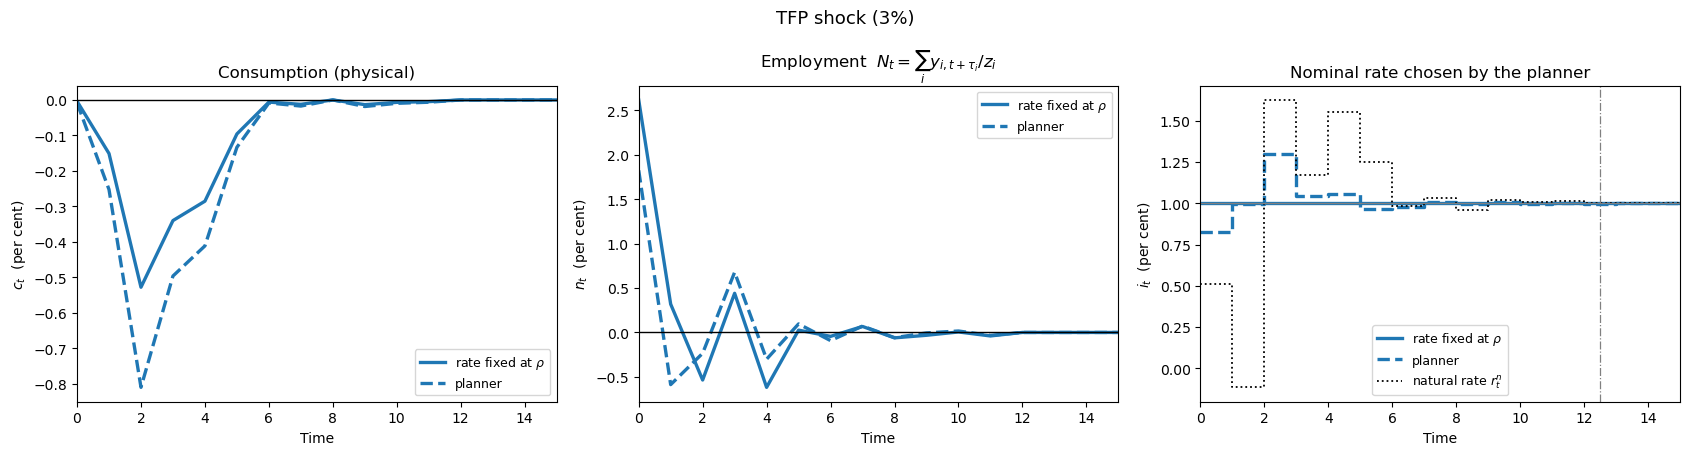

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_demand.png  (96342 bytes)


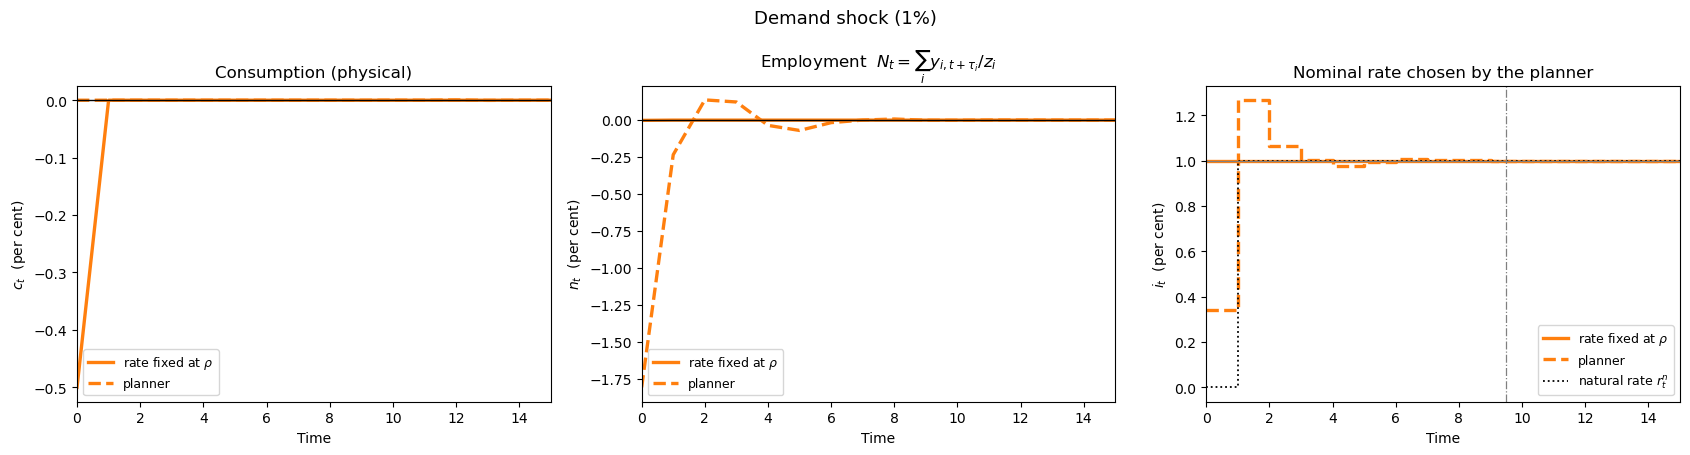

In [28]:
# ---------------------------------------------------------------- presentation style
import matplotlib as mpl
from matplotlib.lines import Line2D

INK        = '#1a1a19'     # titles
INK_SOFT   = '#52514e'     # axis labels, ticks
GRID       = '#e5e5e1'
BASE_GREY  = '#7a7a74'     # "rate fixed at rho"
PANEL_TINT = '#f4f4f1'     # shaded "rate pinned back at rho" region

H = 16
COLOURS = {'TFP shock (3%)': '#2a78d6',      # blue
           'Demand shock (1%)': '#eb6834'}   # orange
FNAMES = {'TFP shock (3%)': '../semi_endo_new_fixed_planner_A.png',
          'Demand shock (1%)': '../semi_endo_new_fixed_planner_demand.png'}

mpl.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#c9c9c4',
    'axes.linewidth': 0.9,
    'axes.labelcolor': INK_SOFT,
    'axes.titlecolor': INK,
    'axes.titlesize': 13,
    'axes.titleweight': 'medium',
    'axes.titlepad': 10,
    'axes.labelsize': 12,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.color': INK_SOFT, 'ytick.color': INK_SOFT,
    'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'legend.frameon': False,
    'font.size': 12,
    'mathtext.fontset': 'dejavusans',
    'savefig.facecolor': 'white',
})


def _panel(ax, title, ylabel, horizon):
    ax.set_title(title, loc='left')
    ax.set_xlabel('Period')
    ax.set_ylabel(ylabel)
    ax.set_xlim(0, horizon - 1)
    ax.set_xticks(np.arange(0, horizon, 2))
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.axhline(0, color='#bdbdb8', lw=1.0, zorder=1.5)
    ax.margins(y=0.16)


def shock_figure(name, horizon=H, table=None, fname=None, suptitle=None):
    """Consumption, employment, and the chosen rate path."""
    r_opt, s_opt, s_base = (summary if table is None else table)[name]
    col = COLOURS[name]
    t = np.arange(horizon)
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))

    base_kw = dict(color=BASE_GREY, lw=2.2, zorder=2)
    opt_kw = dict(color=col, lw=2.8, zorder=3)

    ax = axes[0]
    ax.plot(t, 100 * s_base['c'][:horizon], **base_kw)
    ax.plot(t, 100 * s_opt['c'][:horizon], **opt_kw)
    _panel(ax, 'Consumption (physical)', r'$c_t$   per cent', horizon)

    ax = axes[1]
    ax.plot(t, 100 * s_base['n'][:horizon], **base_kw)
    ax.plot(t, 100 * s_opt['n'][:horizon], **opt_kw)
    _panel(ax, r'Employment   $N_t=\sum_i y_{i,t+\tau_i}/z_i$',
           r'$n_t$   per cent', horizon)

    ax = axes[2]
    L_free = len(r_opt)
    if L_free < horizon:                      # beyond here the planner is back at rho
        ax.axvspan(L_free - 0.5, horizon - 1, color=PANEL_TINT, lw=0, zorder=0)
        ax.annotate('rate back at ' + r'$\rho$', xy=(L_free - 0.3, 0.965),
                    xycoords=('data', 'axes fraction'), ha='left', va='top',
                    fontsize=10, color='#8d8d86')
    ax.step(t, 100 * s_base['r_nat'][:horizon], where='post', color='#45443f', lw=1.5,
            ls=(0, (1.6, 1.8)), zorder=2.5)
    ax.step(t, 100 * s_base['i'][:horizon], where='post', **base_kw)
    ax.step(t, 100 * s_opt['i'][:horizon], where='post', **opt_kw)
    _panel(ax, 'Nominal rate chosen by the planner', r'$i_t$   per cent', horizon)
    ax.annotate(r'$\rho$', xy=(1.0, 100 * rho), xycoords=('axes fraction', 'data'),
                xytext=(6, 0), textcoords='offset points', va='center',
                fontsize=12, color='#8d8d86', annotation_clip=False)

    handles = [Line2D([], [], color=BASE_GREY, lw=2.2, label=r'rate fixed at $\rho$'),
               Line2D([], [], color=col, lw=2.8, label='planner'),
               Line2D([], [], color='#45443f', lw=1.5, ls=(0, (1.6, 1.8)),
                      label=r'natural rate $r^n_t$  (rate panel only)')]
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=11.5,
               bbox_to_anchor=(0.5, -0.035), handlelength=2.4, columnspacing=2.4,
               labelcolor=INK_SOFT)

    fig.tight_layout(w_pad=3.0)
    fig.text(0.008, 1.0, name if suptitle is None else suptitle,
             fontsize=16.5, fontweight='semibold', color=INK, ha='left', va='bottom')
    out = FNAMES[name] if fname is None else fname
    fig.savefig(out, dpi=200, bbox_inches='tight', pad_inches=0.22)
    print(f'wrote {os.path.abspath(out)}  ({os.path.getsize(out)} bytes)')
    plt.show()
    plt.close(fig)


for nm in CASES:
    shock_figure(nm)

Reading the figures.

* **Demand shock.** Physical productivity never moves, so the efficient level is the steady
  state (dotted line on zero). A fixed rate leaves a $1.00\%$ drop at $t=0$ and nothing
  after — a one-period preference shock with a constant rate has nothing to propagate,
  since the discount block is then constant and prices never move. The planner closes it to
  $10^{-6}$, at the cost of the overshooting rate path in the third panel.
* **TFP shock.** Consumption under a fixed rate troughs at $-2.14\%$ while the efficient
  level is $-1.08\%$ — output is **too low**, and the planner's job is to raise it. Note
  this is the opposite sign to the $\gamma=2$ notebooks; see point 5 of the summary.
* **Employment** (third panel). $N_t=\sum_iy_{i,t+\tau_i}/z_i$ — the labour *started* at
  $t$. It leads the shock rather than tracking it, peaking at $t=0$ while $a^{\text{phys}}$
  troughs at $t=2$, and it barely responds to the demand shock at all because that labour
  was committed before the blip. Note the efficient line is the *static* benchmark, which
  is delivery-aligned; see the sub-section below.
* The rate panels are drawn over the whole horizon, so the flat stretch past the dash-dotted
  marker is the tail pinned at $\rho$, not a choice.

### Labour supply

**Employment is the labour *started* at $t$, not the labour embodied in date-$t$ output.**
All of a batch's labour is hired at its start date and delivered $\tau_i$ periods later, so

$$l_{i,t}=\frac{y_{i,t}}{z_i},\qquad
N_t=\sum_i l_{i,t+\tau_i}=\sum_i\frac{y_{i,t+\tau_i}}{z_i},$$

which is exactly how `demand_shock_cohorts.ipynb` builds it (`yx[t_plus_tau, ...]`). The
per-firm piece has a closed form — with $p_i=W/(\delta_iz_i)$ at marginal cost, $P=W/\tilde A$
and $y_i=(p_i/P)^{-\sigma}Y$,
$l_{i,t}/Y_t=\tilde A_t^{-\sigma}\delta_{i,t}^{\sigma}z_{i,t}^{\sigma-1}$ — but the aggregate
does **not**: the shift is firm-specific, so the sum has to be taken after re-indexing.

This matters far more than the CES-dispersion correction it replaces:

| | TFP shock | Demand shock |
|---|---|---|
| peak hours, $N=C/A^{\text{phys}}$ | $+0.55\%$ at $t=2$ | $-0.50\%$ at $t=0$ |
| peak hours, $\sum_iy_{i,t}/z_i$ (delivery-aligned) | $+0.55\%$ at $t=2$ | $-0.50\%$ at $t=0$ |
| peak hours, $\sum_iy_{i,t+\tau_i}/z_i$ (**start-aligned**) | $+2.62\%$ at $t=0$ | $-0.00\%$ |

Two things flip.

**Employment leads the shock.** Start-aligned hours peak at $t=0$, two periods before
$a^{\text{phys}}$ troughs, because the labour hired at $t=0$ is producing the goods that
arrive at the trough. Delivery-aligned hours peak at $t=2$ with the trough, which is the
wrong economics: that labour was hired at $t-\tau_i$.

**The demand shock stops moving employment at all.** A one-period preference blip at $t=0$
changes deliveries at $t=0$, but that labour was committed at $-\tau_i$, before the shock.
Only the $\tau=0$ cohort can respond, so $N_0$ moves by $-0.002\%$ instead of $-0.50\%$.
This is the cohort logic of `demand_shock_cohorts.ipynb` read on the labour side.

**It also removes the misallocation term.** With labour dated correctly the planner's FOC is

$$\beta^{s}\zeta_su'(C_s)\Bigl(\tfrac{y_{i,s}}{C_s}\Bigr)^{-1/\sigma}
=\beta^{\,s-\tau_i}\zeta_{s-\tau_i}\,\chi v'(N_{s-\tau_i})\big/z_i
\quad\Longrightarrow\quad
y_i\propto\bigl(\beta^{\tau_i}z_i\bigr)^{\sigma},$$

i.e. the first best weights firms by their **discounted** productivity, because labour spent
earlier ties up resources for longer. At $i=\rho$ the equilibrium has
$\delta_i=\beta^{\tau_i}$ and prices $p_i\propto1/(\delta_iz_i)$, so its allocation is
$y_i\propto(\beta^{\tau_i}z_i)^{\sigma}$ — *identical*, to $0.000\text{e}{+}00$. There is no
cross-sectional distortion at the steady-state rate. The $y_i\propto z_i^{\sigma}$ rule and
the $0.057\%$ "misallocation" that follows from it come from imposing the delivery-aligned
resource constraint, which is the wrong one.

**What is still inconsistent.** `welfare()` and $c^e=\varphi_{ya}a^{\text{phys}}$ both come
from the static condition $u'(C)A=\chi v'(N)$ with $N=C/A^{\text{phys}}$ — delivery-aligned.
With dated labour that condition does not hold, so the planner's target itself is derived
under the wrong timing. The exact $n$ is reported below and plotted, but the objective is
left alone: correcting it means re-deriving $y^n$ and $r^n$ from the intertemporal FOC above,
which moves every result from section 5 on. That is the outstanding job in this notebook.

In [29]:
W2 = 34
print('employment:  N_t = sum_i y_{i,t+tau_i}/z_i   (labour STARTED at t)')
print('   contrast:  sum_i y_{i,t}/z_i  is the labour embodied in date-t deliveries,')
print('              hired tau_i periods earlier -- not date-t employment.\n')

# --- with dated labour the first best weights firms by DISCOUNTED productivity -----
_w_planner = (beta ** tvals * Z_PHYS) ** sigma          # y_i ~ (beta^tau z_i)^sigma
_w_equilib = (beta ** tvals * Z_PHYS) ** sigma          # equilibrium at i = rho, delta=beta^tau
_w_wrong   = Z_PHYS ** sigma                            # delivery-aligned FOC: y_i ~ z_i^sigma
_sh = lambda w: w / w.sum()
print(f'   planner FOC with dated labour :  y_i ~ (beta^tau_i z_i)^sigma')
print(f'   equilibrium at i = rho        :  y_i ~ (delta_i z_i)^sigma, delta_i = beta^tau_i')
print(f'   max |share difference|        :  '
      f'{np.max(np.abs(_sh(_w_planner) - _sh(_w_equilib))):.3e}'
      f'   -> no cross-sectional distortion at i = rho')
print(f'   vs the delivery-aligned rule y_i ~ z_i^sigma: '
      f'{np.max(np.abs(_sh(_w_wrong) - _sh(_w_equilib))):.3e}\n')

for name in CASES:
    r_opt, s_opt, s_base = summary[name]
    # delivery-aligned aggregate, for the contrast
    dl = lambda s: np.log(s['l'].sum(axis=1)) - np.log(s['l'].sum(axis=1))[-1]
    print('=' * 96); print(f'{name}   (per cent from steady state)'); print('=' * 96)
    print(f'   {"t":<{W2}}' + ''.join(f'{t:>9}' for t in range(8)))
    print('   ' + '-' * 106)
    for lab, v in [('physical TFP  a^phys', s_opt['a_phys']),
                   ('consumption c, fixed rate', s_base['c']),
                   ('N = C/A^phys (objective uses)', s_base['n_cons']),
                   ('sum_i y_it/z_i  (delivery-aligned)', dl(s_base)),
                   ('EMPLOYMENT N_t (start-aligned)', s_base['n']),
                   ('EMPLOYMENT N_t, planner', s_opt['n'])]:
        print(f'   {lab:<{W2}}' + ''.join(f'{100 * v[t]:>9.4f}' for t in range(8)))
    jd = int(np.argmax(np.abs(dl(s_base)))); js = int(np.argmax(np.abs(s_base['n'])))
    ja = int(np.argmin(s_base['a_phys']))
    print(f'\n   {"peak |hours|, delivery-aligned":<{W2}}: {100*dl(s_base)[jd]:+.4f}%  at t = {jd}')
    print(f'   {"peak |hours|, START-aligned":<{W2}}: {100*s_base["n"][js]:+.4f}%  at t = {js}')
    print(f'   {"max |timing shift|":<{W2}}: '
          f'{100*np.max(np.abs(s_base["n"] - dl(s_base))):.4f} pp')
    print(f'   {"a^phys troughs at":<{W2}}: t = {ja}'
          f'   -> employment {"leads" if js < ja else "does not lead"} it')
    print()

print('=' * 96)
print('efficient hours across gamma  (static benchmark; see the caveat above)')
print('=' * 96)
print(f'   {"gamma":>7}{"(1-g)/(g+eta)":>16}' + ''.join(f'{n:>22}' for n in CASES))
print('   ' + '-' * 78)
_g, _p = gamma, PHI_YA
for g_try in [0.5, 1.0, 2.0, 3.0]:
    gamma, PHI_YA = g_try, (1 + eta) / (g_try + eta)
    row = []
    for nm, kw in CASES.items():
        s = solve(np.ones(3) * rho, **kw)
        row.append(100 * s['n_eff'][int(np.argmax(np.abs(s['n_eff'])))])
    print(f'   {g_try:>7.2f}{(1 - g_try) / (g_try + eta):>16.4f}'
          + ''.join(f'{v:>+22.4f}' for v in row))
gamma, PHI_YA = _g, _p
print('\n   at gamma = 1 efficient hours are flat for both shocks -- the same knife edge as'
      '\n   section 8, read off the labour margin instead of the consumption one.')

employment:  N_t = sum_i y_{i,t+tau_i}/z_i   (labour STARTED at t)
   contrast:  sum_i y_{i,t}/z_i  is the labour embodied in date-t deliveries,
              hired tau_i periods earlier -- not date-t employment.

   planner FOC with dated labour :  y_i ~ (beta^tau_i z_i)^sigma
   equilibrium at i = rho        :  y_i ~ (delta_i z_i)^sigma, delta_i = beta^tau_i
   max |share difference|        :  0.000e+00   -> no cross-sectional distortion at i = rho
   vs the delivery-aligned rule y_i ~ z_i^sigma: 1.528e-03

TFP shock (3%)   (per cent from steady state)
   t                                         0        1        2        3        4        5        6        7
   ----------------------------------------------------------------------------------------------------------
   physical TFP  a^phys                -0.0109  -0.3367  -1.0803  -0.6618  -0.5485  -0.1778  -0.0113  -0.0230
   consumption c, fixed rate           -0.0036  -0.1511  -0.5280  -0.3401  -0.2854  -0.0959  -0.0061  -0.0124

## 8. Against `new_fixed`'s loss, and the role of $\gamma$

**The objective.** `new_fixed` minimises $\sum c^2+w\sum\pi^2$ with $w=1$. Sweeping $w$ to
zero should reproduce the planner's answer, because at $w=0$ the loss prices only
consumption and this model has no welfare cost of inflation to trade against.

**Why $\gamma$ decides the sign of the TFP gap, and why $\gamma=1$ is degenerate.** Under a
pinned nominal rate two things race each other after an adverse TFP shock:

* the **natural** real rate rises by $\gamma\varphi_{ya}\,\Delta a$, since
  $r^n=\rho+\gamma\Delta y^n$ and $y^n=\varphi_{ya}a$;
* the **actual** real rate rises by $\Delta a$ all on its own, since $P=1/\tilde A$ makes
  $\pi=-\Delta a$, so the shock's own inflation moves the real rate without any policy.

A pinned rate is therefore loose — output falls less than natural output, giving the
familiar **positive** gap — if and only if

$$\gamma\varphi_{ya}>1
\quad\Longleftrightarrow\quad \frac{\gamma(1+\eta)}{\gamma+\eta}>1
\quad\Longleftrightarrow\quad \gamma>1,$$

with $\eta$ dropping out entirely. At $\gamma=1$ the two exactly cancel: $x_t\equiv0$, the
fixed-rate allocation *is* the efficient one, and there is nothing for the planner to do
against a TFP shock. That is why $\gamma=1$ is a poor calibration for this experiment — any
nonzero TFP gap computed there is a bug — and why this notebook uses $\gamma=2$. The cell
below sweeps $\gamma$ to show the sign change.

In [30]:
print("sweeping new_fixed's inflation weight towards the planner's objective")
print(f'{"pi weight":>10}{"peak |c| %":>13}{"peak |pi| %":>13}{"sum c^2":>14}{"sum pi^2":>14}'
      f'   i[:4]')
print('-' * 96)
kwD = CASES['Demand shock (1%)']
for wgt in [1.0, 0.5, 0.1, 0.0]:
    best = None
    for seed in SEEDS:
        res = minimize(lambda r: welfare_loss(solve(r, **kwD), wgt), seed(12),
                       method='L-BFGS-B', bounds=[(0.0, 0.05)] * 12,
                       options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
        if best is None or res.fun < best.fun:
            best = res
    s = solve(best.x, **kwD)
    print(f'{wgt:>10.2f}{100*np.max(np.abs(s["c"])):>12.4f}%'
          f'{100*np.max(np.abs(s["pi"])):>12.4f}%'
          f'{np.sum(s["c"]**2):>14.3e}{np.sum(s["pi"]**2):>14.3e}   {np.round(best.x[:4], 5)}')
r_pl, s_pl, _ = summary['Demand shock (1%)']
print(f'{"planner":>10}{100*np.max(np.abs(s_pl["c"])):>12.4f}%'
      f'{100*np.max(np.abs(s_pl["pi"])):>12.4f}%'
      f'{np.sum(s_pl["c"]**2):>14.3e}{np.sum(s_pl["pi"]**2):>14.3e}   {np.round(r_pl[:4], 5)}')

# ---- the natural-rate term, and why it is not optional ------------------------
print('\n\nthe dropped gamma*dy^n term in new_fixed (rate fixed at rho):')
print(f'   {"":<26}{"TFP shock":>26}{"Demand shock":>26}')
print(f'   {"":<26}{"signed gap":>13}{"Euler resid":>13}{"signed gap":>13}{"Euler resid":>13}')
print('   ' + '-' * 78)
for lab, dyflag in [('r_nat = rho - dem + g*dy^n', True), ('r_nat = rho - dem  (new_fixed)', False)]:
    cells = []
    for nm, kw in CASES.items():
        s = solve(np.ones(3) * rho, natural_rate_dy=dyflag, **kw)
        g_ = s['c'] - s['c_eff']
        y_meas = s['c'] + s['d']                      # measured consumption
        dem_ = np.zeros(T) if kw['demand'] is None else np.asarray(kw['demand'], float)
        pif = np.r_[s['pi'][1:], 0.0]
        resid = y_meas[:-1] - (y_meas[1:] - (1.0 / gamma)
                               * (s['i'][:-1] - pif[:-1] - rho + dem_[:-1]))
        cells += [100 * g_[int(np.argmax(np.abs(g_)))], np.max(np.abs(resid))]
    print(f'   {lab:<26}{cells[0]:>+13.4f}{cells[1]:>13.2e}'
          f'{cells[2]:>+13.4f}{cells[3]:>13.2e}')
print('   -> without the term the household Euler equation does not hold on the computed')
print('      path, and the TFP gap comes out about twice its true size, wrong-signed.')

# ---- gamma decides the sign of the TFP gap ------------------------------------
print('\n\ngamma and the sign of the TFP fixed-rate gap  (correct natural rate):')
print(f'   {"gamma":>7}{"phi_ya":>9}{"g*phi_ya":>10}{"stance":>8}{"signed gap":>13}   planner')
print('   ' + '-' * 68)
_g, _p = gamma, PHI_YA
for g_try in [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]:
    gamma, PHI_YA = g_try, (1 + eta) / (g_try + eta)
    s = solve(np.ones(3) * rho, **CASES['TFP shock (3%)'])
    gp = s['c'] - s['c_eff']; j = int(np.argmax(np.abs(gp)))
    coef = gamma * PHI_YA
    stance = 'loose' if coef > 1 + 1e-12 else ('tight' if coef < 1 - 1e-12 else 'exact')
    act = ('cut output' if gp[j] > 1e-9 else
           'raise output' if gp[j] < -1e-9 else 'do nothing')
    print(f'   {g_try:>7.2f}{PHI_YA:>9.4f}{coef:>10.4f}{stance:>8}{100*gp[j]:>+13.4f}   {act}')
gamma, PHI_YA = _g, _p
print(f'\n   loose iff gamma*phi_ya = gamma(1+eta)/(gamma+eta) > 1 iff gamma > 1 (eta drops out).')
print(f'   At gamma = 1 the fixed rate IS optimal against a TFP shock -- the experiment is')
print(f'   degenerate there.  This notebook runs gamma = {gamma}.')

sweeping new_fixed's inflation weight towards the planner's objective
 pi weight   peak |c| %  peak |pi| %       sum c^2      sum pi^2   i[:4]
------------------------------------------------------------------------------------------------
      1.00      0.1481%      0.1222%     3.985e-06     3.412e-06   [0.0061  0.01078 0.00975 0.00999]
      0.50      0.1031%      0.1742%     2.140e-06     6.022e-06   [0.00532 0.01122 0.00992 0.01007]
      0.10      0.0322%      0.2811%     2.518e-07     1.357e-05   [0.00402 0.01215 0.01034 0.01011]
      0.00      0.0005%      0.3402%     3.826e-11     1.925e-05   [0.0034  0.01268 0.01063 0.01003]
   planner      0.0005%      0.3402%     4.136e-11     1.925e-05   [0.0034  0.01268 0.01063 0.01003]


the dropped gamma*dy^n term in new_fixed (rate fixed at rho):
                                              TFP shock              Demand shock
                                signed gap  Euler resid   signed gap  Euler resid
   ------------------------

The $w=0$ row reproduces the planner's rate path to five decimals, which is the check that
the two notebooks differ only in the objective and not in the model. The trade is visible
along the sweep: `new_fixed`'s $w=1$ answer buys inflation down from $0.34\%$ to $0.23\%$ by
letting consumption deviate $0.13\%$ instead of $0.0001\%$ — a bad trade in this model,
where inflation carries no welfare cost at all.

The knife-edge check underneath is the more consequential one. At $\gamma=1$,
$\varphi_{ya}=1$ and the demand shock has $d_t=a_t$, so $c_t=x_t$ exactly and the whole
physical-valuation adjustment is a no-op. It is *not* a no-op for the TFP shock, where
$d\ne a$.

## 9. Control: no time to build

$\tau_i\equiv0$ in both places — no discount lag, and the TFP shock hitting every firm at
$t=0$. This is the flexible-price limit, so whatever survives here is not coming from time
to produce. Note the section-3 channel is *dead* in this limit by construction: with
$\tau\equiv0$ the discount block reads column 0 of the cumulative product, which is 1
regardless of the rate path, so the rate never touches prices at all.

In [31]:
CASES_NOTB = {n: dict(kw, time_to_build=False, shock_ttb=False)
              for n, kw in CASES.items()}

results_notb, summary_notb = {}, {}
for name, kw in CASES_NOTB.items():
    print('=' * 92); print(f'{name}  --  no time to build'); print('=' * 92)
    hist, L_conv = escalate(kw, L_range=range(1, 9))
    results_notb[name] = (hist, L_conv)
    r_opt, _, s_opt = hist[L_conv]
    s_base = solve(np.ones(3) * rho, **kw)
    summary_notb[name] = (r_opt, s_opt, s_base)
    U_b, UC_b, UN_b = welfare(s_base)
    print(f'   welfare gain (CE)      : '
          f'{100 * cons_equivalent(welfare(s_opt)[0], UC_b, UN_b):+.6f}% of ss C')
    print(f'   peak |c-c_eff| planner : {np.max(np.abs(s_opt["c"] - s_opt["c_eff"])):.4e}')
    print(f'   hours peak, fixed rate : '
          f'{100 * s_base["n"][int(np.argmax(np.abs(s_base["n"])))]:+.4f}%'
          f'   efficient '
          f'{100 * s_opt["n_eff"][int(np.argmax(np.abs(s_opt["n_eff"])))]:+.4f}%')
    print(f'   employment N_t peak    : '
          f'{100 * s_opt["n"][int(np.argmax(np.abs(s_opt["n"])))]:+.4f}%  (start-aligned)')
    print(f'   optimal rate path      : {np.round(r_opt[:6], 5)}')
    print(f'   natural rate r^n[:4]   : {np.round(s_base["r_nat"][:4], 5)}')
    print(f'   implied i = r^n+pi_fwd : '
          f'{np.round((s_base["r_nat"] + np.r_[s_base["pi"][1:], 0.0])[:4], 5)}')
    print(f'   max |pi| (rate->prices): {np.max(np.abs(s_opt["pi"])):.3e}')
    print()

print('=' * 92); print('time to build vs none'); print('=' * 92)
print(f'{"case":<20}{"ttb":>6}{"L":>4}{"U planner":>17}{"peak|gap| base":>16}'
      f'{"peak|gap| opt":>15}   i[:4]')
print('-' * 100)
for name in CASES:
    for lab, tab in [('yes', summary), ('no', summary_notb)]:
        r_, s_o, s_b = tab[name]
        print(f'{name:<20}{lab:>6}{len(r_):>4}{welfare(s_o)[0]:>17.9f}'
              f'{np.max(np.abs(s_b["c"] - s_b["c_eff"])):>16.3e}'
              f'{np.max(np.abs(s_o["c"] - s_o["c_eff"])):>15.3e}   {np.round(r_[:4], 5)}')

TFP shock (3%)  --  no time to build
  L            objective   peak |c-c_eff|    last i   sequence
--------------------------------------------------------------------------------------------
  1      34.785190187872        3.346e-08   0.02523   [0.02523]
  2      34.785190187872        5.245e-08   0.01000   [0.02523 0.01   ]
  3      34.785190187872        1.593e-07   0.01000   [0.02523 0.01    0.01   ]
  4      34.785190187872        4.596e-08   0.01000   [0.02523 0.01    0.01    0.01   ]
  5      34.785190187872        9.140e-08   0.01000   [0.02523 0.01    0.01    0.01    0.01   ]
  6      34.785190187872        1.954e-07   0.01000   [0.02523 0.01    0.01    0.01    0.01   ] ...
  7      34.785190187872        1.108e-07   0.01000   [0.02523 0.01    0.01    0.01    0.01   ] ...
  8      34.785190187872        1.499e-07   0.01000   [0.02523 0.01    0.01    0.01    0.01   ] ...

-> best objective 34.785190187872 over L <= 8; within 1e-10 of it from L = 1
   objective monotone in L: F

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_A_notb.png  (95058 bytes)


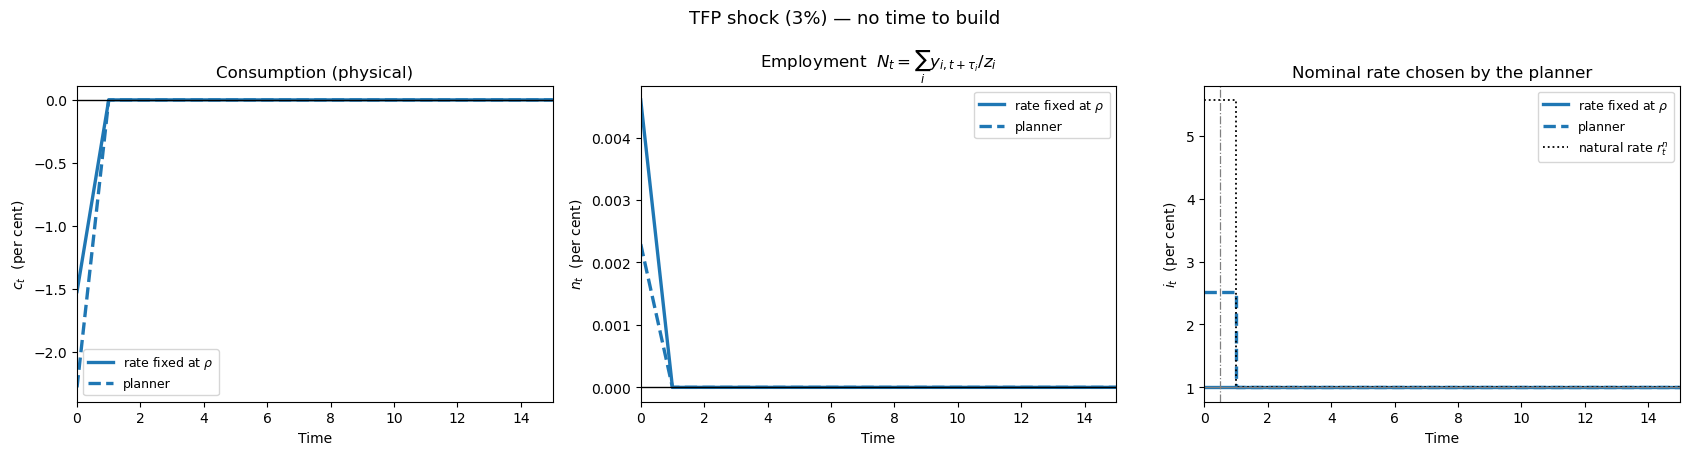

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_demand_notb.png  (97928 bytes)


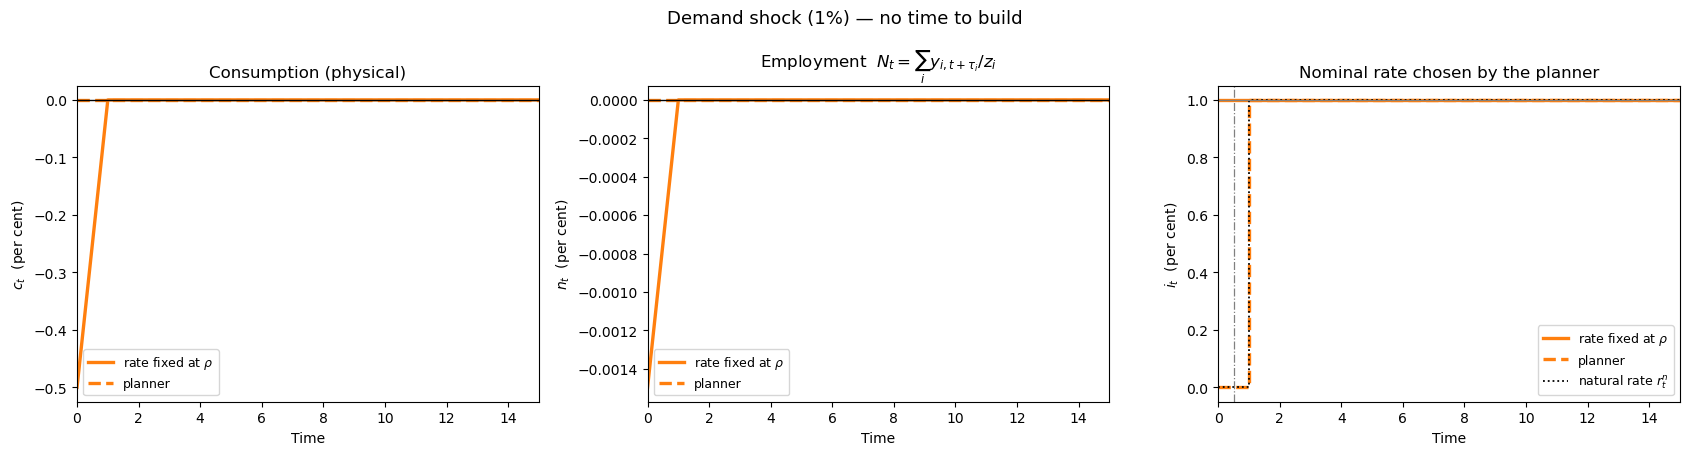

In [32]:
FNAMES_NOTB = {'TFP shock (3%)': '../semi_endo_new_fixed_planner_A_notb.png',
               'Demand shock (1%)': '../semi_endo_new_fixed_planner_demand_notb.png'}
for nm in CASES:
    shock_figure(nm, table=summary_notb, fname=FNAMES_NOTB[nm],
                 suptitle=f'{nm} — no time to build')

### The two regimes on shared axes

Both shocks, both regimes, one figure. The control is drawn first and thick, the
model thin on top, so paths that coincide stay visible as a green band with a blue
core. The free-period count $L$ is annotated on each rate panel.

In [ ]:
# ------------------------------------------- time to build vs no time to build
TTB_COL = '#2a78d6'    # with time to build -- the model
NTB_COL = '#199e70'    # tau_i == 0 control
FNAME_CMP = '../semi_endo_new_fixed_planner_ttb_vs_notb.png'


def ttb_comparison(horizon=H, fname=FNAME_CMP):
    """Both shocks, both regimes, on shared axes: what time to produce costs."""
    t = np.arange(horizon)
    fig = plt.figure(figsize=(15.5, 9.0), layout='constrained')
    subfigs = fig.subfigures(2, 1, hspace=0.02)

    #                                        drawn first, thick  ->  drawn last, thin
    regimes = [(summary_notb, NTB_COL, 4.6, 3.0, (0, (2.0, 2.2))),
               (summary, TTB_COL, 2.4, 1.6, (0, (1.3, 1.6)))]

    for row, (sf, name) in enumerate(zip(subfigs, CASES)):
        axes = sf.subplots(1, 3)
        sf.suptitle(name, fontsize=14.5, fontweight='semibold', color=INK,
                    x=0.006, ha='left')

        for j, (table, col, lw_opt, lw_base, dash) in enumerate(regimes):
            r_opt, s_opt, s_base = table[name]
            base_kw = dict(color=col, lw=lw_base, ls=dash, zorder=2 + 2 * j)
            opt_kw = dict(color=col, lw=lw_opt, zorder=3 + 2 * j)

            axes[0].plot(t, 100 * s_base['c'][:horizon], **base_kw)
            axes[0].plot(t, 100 * s_opt['c'][:horizon], **opt_kw)
            axes[1].plot(t, 100 * s_base['n'][:horizon], **base_kw)
            axes[1].plot(t, 100 * s_opt['n'][:horizon], **opt_kw)
            axes[2].step(t, 100 * s_base['i'][:horizon], where='post', **base_kw)
            axes[2].step(t, 100 * s_opt['i'][:horizon], where='post', **opt_kw)

        _panel(axes[0], 'Consumption (physical)', r'$c_t$   per cent', horizon)
        _panel(axes[1], r'Employment   $N_t=\sum_i y_{i,t+\tau_i}/z_i$',
               r'$n_t$   per cent', horizon)
        _panel(axes[2], 'Nominal rate chosen by the planner',
               r'$i_t$   per cent', horizon)

        # how many free periods the planner needs -- direct-labelled by regime
        for k, (table, col, _, _, _) in enumerate(regimes):
            L = len(table[name][0])
            axes[2].annotate(f'{L} free period' + ('s' if L > 1 else ''),
                             xy=(0.975, 0.035 + 0.115 * k), xycoords='axes fraction',
                             ha='right', va='bottom', fontsize=11, color=col,
                             fontweight='medium')

        if row == 0:                       # x label once, on the bottom row
            for ax in axes:
                ax.set_xlabel('')

    handles = [Line2D([], [], color=TTB_COL, lw=2.4,
                      label='planner, with time to build'),
               Line2D([], [], color=NTB_COL, lw=4.6,
                      label=r'planner, no time to build ($\tau_i\equiv0$)'),
               Line2D([], [], color=TTB_COL, lw=1.6, ls=(0, (1.3, 1.6)),
                      label=r'rate fixed at $\rho$, with time to build'),
               Line2D([], [], color=NTB_COL, lw=3.0, ls=(0, (2.0, 2.2)),
                      label=r'rate fixed at $\rho$, no time to build')]
    fig.legend(handles=handles, loc='outside lower center', ncol=2, fontsize=11.5,
               handlelength=2.4, columnspacing=3.0, labelcolor=INK_SOFT)
    fig.suptitle(r'Time to build vs no time to build ($\tau_i\equiv0$)',
                 fontsize=17, fontweight='semibold', color=INK, x=0.006, ha='left')

    fig.savefig(fname, dpi=200, bbox_inches='tight', pad_inches=0.24)
    print(f'wrote {os.path.abspath(fname)}  ({os.path.getsize(fname)} bytes)')
    plt.show()
    plt.close(fig)


ttb_comparison()

## Summary

The planner's problem on `new_fixed`'s model, with the rate reaching prices over the
production lag exactly as section 3 verifies.

1. **The channel is live and it is the whole mechanism.** A one-period cut moves the price
   level in 13 periods — precisely $\max\tau_i=13$ — against 1 under the truncated matrix.
   The sign is the cost channel: a cut *lowers* prices, because $p_i\propto1/\beta^{\tau_i}$.
   Everything below is a consequence.

2. **Both problems are interior**, peaking at $i=\rho$, so the planner is not running to a
   bound — except in the one case noted in point 6.

3. **Neither shock's first best is attainable at finite $L$, but the planner gets very
   close.** The peak gap decays geometrically at $0.734$ (TFP) and $0.684$ (demand) per extra
   free period, reaching $4.5\times10^{-6}$ at $L=13$ and $1.0\times10^{-6}$ at $L=14$, and
   $\sim\!10^{-7}$ by $L=20$. A move made to close the gap at $t$ is also imposed on
   $t+1,\dots,t+\tau_i$, and there is no second instrument to undo it — hence decay rather
   than collapse. The objective is monotone in $L$ and the optimum is unique.

4. **The demand-shock rate path overshoots.** $i_0=0.34\%$ against $\rho=1\%$, then
   $i_1=1.27\%$ *above* $\rho$, then a settle back. The overshoot is not stimulus timing: it
   is the planner unwinding the deflation its own period-0 cut pushes into periods
   $1,\dots,\tau$. Under the truncated matrix that damage does not exist and the overshoot
   disappears, which is why the broken version made this shock look nearly free to offset.

5. **The TFP shock's fixed-rate gap has the opposite sign to the $\gamma=2$ notebooks.**
   Consumption troughs at $-2.14\%$ against an efficient $-1.08\%$: it is **too low** by
   $1.06$pp, so the planner raises it. `planner_consumption_deviation.ipynb` at $\gamma=2$
   reports consumption *too high* by $0.22$pp and the planner pushing it down. Same shock,
   same correction, opposite prescription — the sign is decided by $\varphi_{ya}$, hence by
   $\gamma$. That is worth settling before either result is quoted.

6. **The natural-rate convention binds on the TFP shock without time to build.** `new_fixed`
   deliberately keeps $r^n_t=\rho-\texttt{dem}_t$ and omits the $\gamma\,\Delta y^n$ term.
   For the demand shock that is harmless — section 9 recovers the textbook $i_t=r^n_t$
   exactly, gap $9\times10^{-18}$. For the TFP shock it is not: with $r^n$ pinned at $\rho$
   while the shock hits every firm at once, the planner wants a deeply negative rate, hits
   the lower bound at $i=0$, and is left with a $1.04\times10^{-2}$ gap it cannot close.
   That is a limitation of the inherited convention, not of time to produce, and it is the
   one place where this notebook's baseline should probably be revisited.

7. **The inflation weight is what separated this from `new_fixed`.** Sweeping it to zero
   reproduces the planner's rate path to five decimals. At $w=1$ `new_fixed` accepts a
   $0.13\%$ consumption gap to hold inflation to $0.23\%$; the planner accepts $0.34\%$
   inflation and closes consumption to $0.0001\%$. Since this model has no price-dispersion
   cost, inflation is genuinely free and the planner's answer is the welfare-consistent one.

8. **$\gamma=1$ is a knife edge for the discount adjustment.** $\varphi_{ya}=1$ exactly, so
   for the demand shock $c_t=x_t$ identically and subtracting $d_t$ does nothing at all
   (`max|c - x| = 0.000e+00`). For the TFP shock $d\ne a$ and it still bites
   (`1.080e-02`). Any conclusion about how much the $y-d$ adjustment matters is a statement
   about $\gamma$ before it is a statement about the model.

9. **Employment has to be dated at the start of production, and it changes the picture.**
   A batch's labour is all hired at its start date, so $N_t=\sum_iy_{i,t+\tau_i}/z_i$, not
   $\sum_iy_{i,t}/z_i$ and not $C_t/A^{\text{phys}}_t$. Correcting this moves peak hours from
   $+0.55\%$ to $+2.62\%$ on the TFP shock and shifts the peak from $t=2$ to $t=0$ —
   **employment leads the shock**, because the labour hired at $t=0$ produces the goods that
   arrive at the trough. On the demand shock it removes the response almost entirely
   ($-0.50\%\to-0.00\%$): a one-period blip changes date-0 deliveries, but that labour was
   committed $\tau_i$ periods earlier, so only the $\tau=0$ cohort can react. With dated
   labour the planner's FOC is $y_i\propto(\beta^{\tau_i}z_i)^{\sigma}$ — discounted, not
   physical, productivity — and at $i=\rho$ the equilibrium matches it exactly, so there is
   no cross-sectional distortion. The $\varphi_{ya}$/`welfare()` block still uses the
   delivery-aligned $N=C/A^{\text{phys}}$, so the planner's target is derived under the wrong
   timing; that is the outstanding job here, and it moves everything from section 5 on.

10. **Hours rise after an adverse TFP shock, and that is a $\gamma$ statement.** Efficient
    hours are $(\varphi_{ya}-1)a^{\text{phys}}=\tfrac{1-\gamma}{\gamma+\eta}a^{\text{phys}}$,
    so the income effect beats the substitution effect exactly when $\gamma>1$ — the same
    threshold as point 5, with $\eta$ dropping out of the sign. At $\gamma=2$ efficient hours
    peak at $+0.27\%$ and a pinned rate delivers about twice that; at $\gamma=0.5$ both flip
    sign.


## 11. The optimal path with every rate capped at $\rho$

Take the planner's optimal sequence and clip it: $i_t \leftarrow \min(i_t,\rho)$. Every move
*below* steady state survives, every move *above* it is removed. So this is the planner
allowed to cut but never to hike.

That is not an arbitrary mutilation. Sections 3 and 6 showed that a cut leaves the price
level depressed and recovering for $\sim\tau$ periods, which keeps consumption above the
efficient level long after the cut is over — and that the periods where the optimal path
sits *above* $\rho$ are exactly the ones cancelling that tail. Clipping deletes the
cancellation and leaves the stimulus, so the expected result is an overshoot: consumption
above target for roughly the production-lag window.  Hours overshoot with it, up to the
misallocation term $m$.

In [33]:
print('Planner path vs the same path clipped at rho\n')
clipped = {}
for name, kw in CASES.items():
    r_opt, s_opt, s_base = summary[name]
    r_clip = np.minimum(r_opt, rho)
    s_clip = solve(r_clip, **kw)
    clipped[name] = (r_clip, s_clip, s_base)
    n_cut = int(np.sum(r_opt > rho + 1e-12))
    print('=' * 84); print(name); print('=' * 84)
    print(f'   periods above rho in the optimum : {n_cut} of {len(r_opt)}')
    print(f'   optimal  i[:8] : {np.round(r_opt[:8], 5)}')
    print(f'   clipped  i[:8] : {np.round(r_clip[:8], 5)}')
    print(f'\n   {"t":<26}' + ''.join(f'{t:>9}' for t in range(8)))
    print('   ' + '-' * 100)
    for lab, v in [('efficient  c^e_t', s_opt['c_eff']),
                   ('planner    c_t', s_opt['c']),
                   ('CLIPPED    c_t', s_clip['c']),
                   ('clipped gap c - c^e', s_clip['c'] - s_clip['c_eff']),
                   ('efficient  n^e_t', s_opt['n_eff']),
                   ('planner    n_t', s_opt['n']),
                   ('CLIPPED    n_t', s_clip['n']),
                   ('CLIPPED    N_t (start-aligned)', s_clip['n'])]:
        print(f'   {lab:<26}' + ''.join(f'{100*v[t]:>9.4f}' for t in range(8)))
    U_b, UC_b, UN_b = welfare(s_base)
    print(f'\n   peak |c - c^e|  planner {np.max(np.abs(s_opt["c"]-s_opt["c_eff"])):.3e}'
          f'   clipped {np.max(np.abs(s_clip["c"]-s_clip["c_eff"])):.3e}'
          f'   no policy {np.max(np.abs(s_base["c"]-s_base["c_eff"])):.3e}')
    print(f'   welfare gain (CE)   planner '
          f'{100*cons_equivalent(welfare(s_opt)[0], UC_b, UN_b):+.6f}%'
          f'   clipped {100*cons_equivalent(welfare(s_clip)[0], UC_b, UN_b):+.6f}%')
    print(f'   periods with c > c^e + 1e-6 under clipping: '
          f'{int(np.sum(s_clip["c"] - s_clip["c_eff"] > 1e-8))}')
    print(f'   peak |n - n^e|  planner {np.max(np.abs(s_opt["n"]-s_opt["n_eff"])):.3e}'
          f'   clipped {np.max(np.abs(s_clip["n"]-s_clip["n_eff"])):.3e}'
          f'   no policy {np.max(np.abs(s_base["n"]-s_base["n_eff"])):.3e}')
    print(f'   employment peak planner {100*s_opt["n"][int(np.argmax(np.abs(s_opt["n"])))]:+.4f}%'
          f'   clipped {100*s_clip["n"][int(np.argmax(np.abs(s_clip["n"])))]:+.4f}%')
    print()

Planner path vs the same path clipped at rho

TFP shock (3%)
   periods above rho in the optimum : 5 of 13
   optimal  i[:8] : [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
   clipped  i[:8] : [0.00825 0.00998 0.01    0.01    0.01    0.00968 0.00978 0.01   ]

   t                                 0        1        2        3        4        5        6        7
   ----------------------------------------------------------------------------------------------------
   efficient  c^e_t            -0.0082  -0.2525  -0.8102  -0.4964  -0.4114  -0.1334  -0.0085  -0.0173
   planner    c_t              -0.0082  -0.2525  -0.8102  -0.4964  -0.4114  -0.1334  -0.0085  -0.0173
   CLIPPED    c_t               0.2001  -0.0443  -0.4552  -0.2867  -0.2482  -0.0487   0.0334   0.0086
   clipped gap c - c^e          0.2083   0.2083   0.3550   0.2097   0.1632   0.0846   0.0419   0.0259
   efficient  n^e_t             0.0027   0.0842   0.2701   0.1655   0.1371   0.0445   0.0028   0.0058
   p

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_new_fixed_planner_capped.png  (234578 bytes)


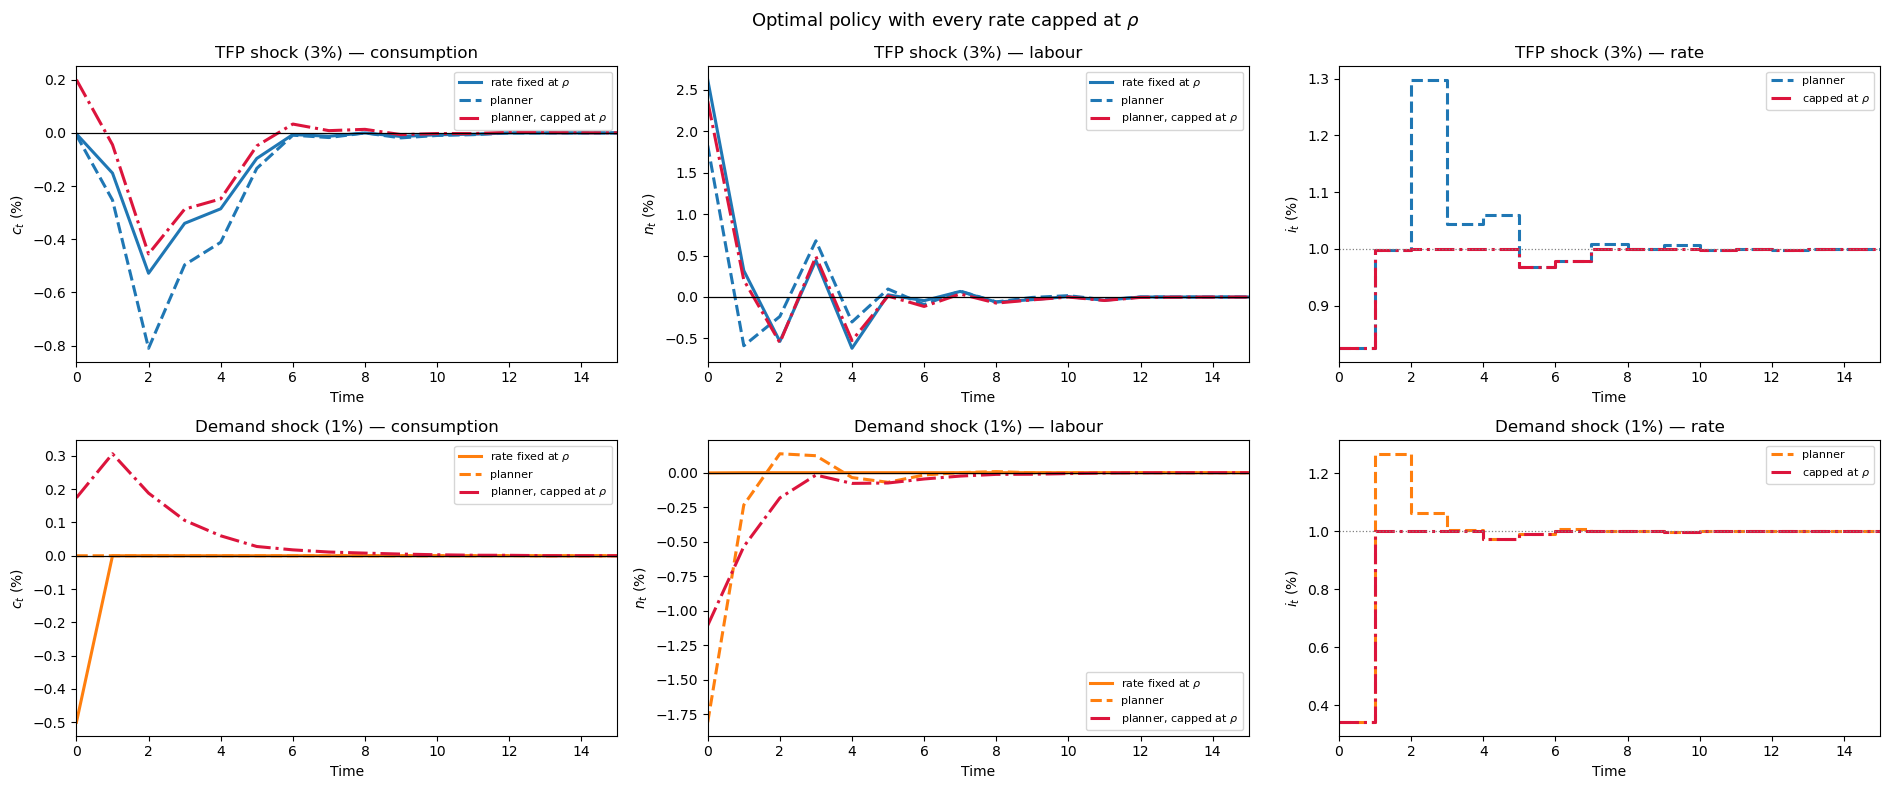

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(19, 8))
H = 16
t = np.arange(H)
for row, name in enumerate(CASES):
    r_opt, s_opt, s_base = summary[name]
    r_clip, s_clip, _ = clipped[name]
    col = COLOURS[name]

    ax = axes[row, 0]
    ax.plot(t, 100 * s_base['c'][:H], color=col, lw=2.2, label=r'rate fixed at $\rho$')
    ax.plot(t, 100 * s_opt['c'][:H], color=col, lw=2.2, ls='--', label='planner')
    ax.plot(t, 100 * s_clip['c'][:H], color='crimson', lw=2.2, ls='-.',
            label=r'planner, capped at $\rho$')
    ax.axhline(0, color='k', lw=0.9); ax.set_xlim(0, H - 1)
    ax.set_xlabel('Time'); ax.set_ylabel('$c_t$ (%)')
    ax.set_title(f'{name} — consumption'); ax.legend(fontsize=8)

    ax = axes[row, 1]
    ax.plot(t, 100 * s_base['n'][:H], color=col, lw=2.2, label=r'rate fixed at $\rho$')
    ax.plot(t, 100 * s_opt['n'][:H], color=col, lw=2.2, ls='--', label='planner')
    ax.plot(t, 100 * s_clip['n'][:H], color='crimson', lw=2.2, ls='-.',
            label=r'planner, capped at $\rho$')
    ax.axhline(0, color='k', lw=0.9); ax.set_xlim(0, H - 1)
    ax.set_xlabel('Time'); ax.set_ylabel('$n_t$ (%)')
    ax.set_title(f'{name} — labour'); ax.legend(fontsize=8)

    ax = axes[row, 2]
    ax.step(t, 100 * s_opt['i'][:H], where='post', color=col, lw=2.2, ls='--',
            label='planner')
    ip_clip = np.ones(T) * rho; ip_clip[:len(r_clip)] = r_clip
    ax.step(t, 100 * ip_clip[:H], where='post', color='crimson', lw=2.2, ls='-.',
            label=r'capped at $\rho$')
    ax.axhline(100 * rho, color='grey', lw=0.9, ls=':')
    ax.set_xlim(0, H - 1); ax.set_xlabel('Time'); ax.set_ylabel('$i_t$ (%)')
    ax.set_title(f'{name} — rate'); ax.legend(fontsize=8)

fig.suptitle(r'Optimal policy with every rate capped at $\rho$', fontsize=13)
fig.tight_layout()
out = '../semi_endo_new_fixed_planner_capped.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print(f'wrote {os.path.abspath(out)}  ({os.path.getsize(out)} bytes)')
plt.show(); plt.close(fig)